Disable just-in-time compilation with XLA.

[1, 1000]
no uniform points
Compiling model...
'compile' took 0.000365 s

Training model...

Step      Train loss              Test loss               Test metric
0         [1.87e+06, 2.58e+01]    [1.87e+06, 2.57e+01]    []  
1000      [2.15e+05, 3.08e+05]    [2.16e+05, 3.05e+05]    []  
2000      [1.46e+05, 2.59e+05]    [1.46e+05, 2.54e+05]    []  
3000      [1.11e+05, 1.51e+05]    [1.12e+05, 1.48e+05]    []  
4000      [6.95e+04, 9.54e+04]    [7.06e+04, 9.40e+04]    []  
5000      [4.34e+04, 7.00e+04]    [4.43e+04, 6.91e+04]    []  
6000      [2.64e+04, 5.10e+04]    [2.69e+04, 5.06e+04]    []  
7000      [1.46e+04, 3.89e+04]    [1.49e+04, 3.89e+04]    []  
8000      [8.27e+03, 3.17e+04]    [8.46e+03, 3.19e+04]    []  
9000      [6.31e+03, 2.55e+04]    [6.47e+03, 2.58e+04]    []  
10000     [5.27e+03, 1.83e+04]    [5.45e+03, 1.85e+04]    []  
11000     [4.26e+03, 1.34e+04]    [4.44e+03, 1.37e+04]    []  
12000     [3.63e+03, 1.00e+04]    [3.

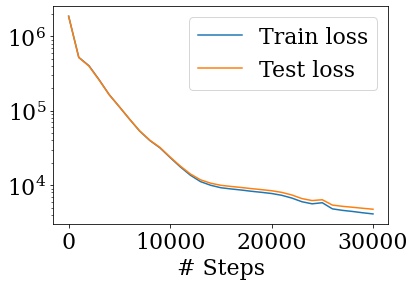

In [26]:
import os
os.environ['DDEBACKEND'] = 'tensorflow'
os.environ['CUDA_VISIBLE_DEVICES'] = '4'

import deepxde as dde 
dde.config.disable_xla_jit()

#class TensorGeometryXTime:
import numpy as np

class GeometryXGeometry:
    def __init__(self, geometry, k):
        self.geometry = geometry
        self.dim = geometry.dim ** k
        self.k = k
    
    def random_points(self, n, random="pseudo"):
        xx = []
        for i in range(self.k):
            xx.append(self.geometry.random_points(n, random=random))
        return np.hstack(xx)
    
    def uniform_points(self, n, boundary=False):
        print('no uniform points')
        return self.random_points(n)
    

"""Backend supported: tensorflow.compat.v1, tensorflow, pytorch"""
import deepxde as dde
import numpy as np

# General parameters
n = 1
k = 2
degree = 2
N_f = 20000
N_f_test = 20000

seed = 1234
dde.config.set_random_seed(seed)
weights = [1000 for i in range(k)]
weights[0] = 1
print(weights)

epochs = 30000

#parameters = [1e-2, 2, 350, "sin"] 
parameters = [1e-3, 2, 350, "sin"] 

# Define sine function
if dde.backend.backend_name == "pytorch":
    sin = dde.backend.pytorch.sin
else:
    from deepxde.backend import tf
    sin = tf.sin

learning_rate, num_dense_layers, num_dense_nodes, activation = parameters


def pde(x, y):
    #y_list = [y[:, i:i+1] for i in range(k)]
    V0, V1 = y[:, 0:1], y[:, 1:2]
    
    dV0_xx = dde.grad.hessian(y, x, component=0, i=0, j=0)
    dV0_yy = dde.grad.hessian(y, x, component=0, i=1, j=1)
    
    dV1_xx = dde.grad.hessian(y, x, component=1, i=2, j=2)
    dV1_yy = dde.grad.hessian(y, x, component=1, i=3, j=3)
    
    #F = k0 ** 4 * sin(k0 * x[:, 0:1]) * sin(k0 * x[:, 1:2]) * sin(k0 * x[:, 2:3]) * sin(k0 * x[:, 3:4])
    
    #dist = (x[:, 0:1] - x[:, 2:3]) #** 2
    
    dist = (x[:, 0:1] - x[:, 2:3]) ** 2 + (x[:, 1:2] - x[:, 3:4])  ** 2
    F =  k0 ** 4 * tf.exp(- dist ** degree)
    #F =  tf.exp(tf.abs(x[:,0:1]** 2 - x[:,2:3] ** 2) / 2)
    
    #F =  tf.exp(tf.abs(x[:,0:1]** 2 - x[:,2:3] ** 2) / 2)
    #F =  tf.exp(tf.abs(x[:,0:1] - x[:,2:3]) / 2)
    
    L1 = - dV0_xx - dV0_yy - k0 ** 2 * V0 - F
    L2 = - dV1_xx - dV1_yy - k0 ** 2 * V1 - V0
    return [L1, L2]

def transform(x, y):
    res1 = x[:, 0:1] * (1 - x[:, 0:1]) * x[:, 1:2] * (1 - x[:, 1:2])
    res2 = x[:, 2:3] * (1 - x[:, 2:3]) * x[:, 3:4] * (1 - x[:, 3:4])

    y_list = [y[:, i:i+1] for i in range(k)]
    
    ys_list = k * [None]
    for i in range(k-1):
        ys_list[i] = y_list[i]
    ys_list[-1] = res1 * res2 * y_list[-1]
    ys = tf.concat(ys_list, axis=1)
    return ys

def l2_error(y_true, y_pred):
    pred = y_true - y_pred
    return np.linalg.norm(pred[:, k-1:k])/np.linalg.norm(y_true[:, k-1:k]) 

geom = dde.geometry.Rectangle([0, 0], [1, 1])
Geom = GeometryXGeometry(geom,2)    

k0 = 2 * np.pi * n
wave_len = 1 / n

data = dde.data.PDE(
    Geom,
    pde,
    train_distribution = 'pseudo',
    num_domain=N_f,
    bcs = [],
    num_test=N_f_test,
)

net = dde.nn.FNN(
    [2 * k] + [num_dense_nodes] * num_dense_layers + [k], activation, "Glorot uniform"
)

net.apply_output_transform(transform)

model = dde.Model(data, net)

model.compile("adam", lr=learning_rate, loss_weights=weights)
#model.compile("adam", lr=learning_rate, metrics=[l2_error], loss_weights=weights, decay = ("inverse time", 10000, 0.5))

losshistory, train_state = model.train(epochs=epochs)
dde.saveplot(losshistory, train_state, issave=True, isplot=True)
    

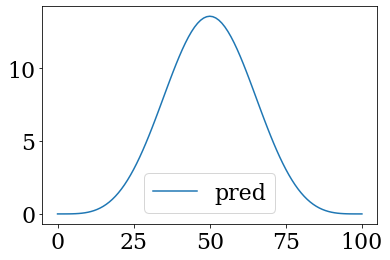

In [30]:
from matplotlib import pyplot as plt
x = np.array([np.arange(101)/100]).T
x_list = [x.T for i in range(2 * k)]
xx = np.concatenate(x_list).T
pred = model.predict(xx)[:, k-1:k]
plt.plot(pred.ravel(), label='pred')
plt.legend()

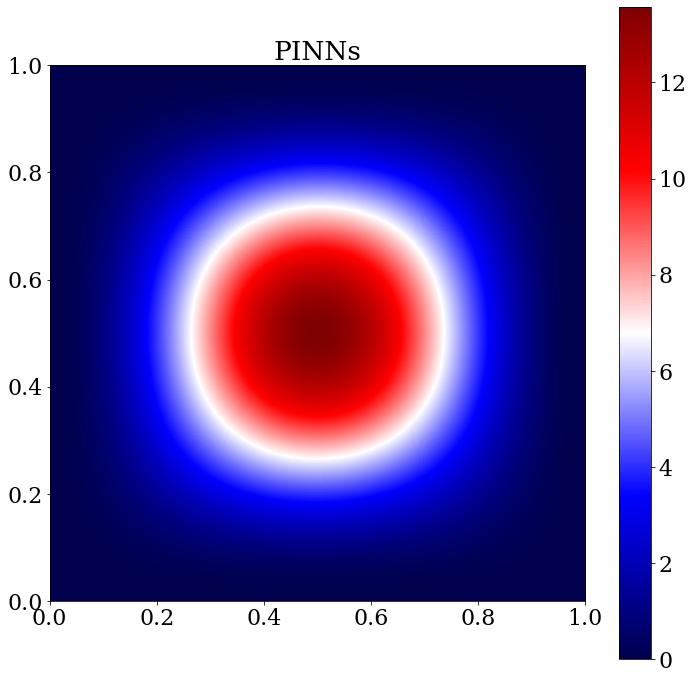

In [31]:
from matplotlib import pyplot as plt
'''            Evaluate field over a specified grid of points              '''
# Square grid with 10 points per wavelength in each direction
Nx = 100
Ny = Nx

# Grid points
xmin, xmax, ymin, ymax = [0,1,0,1]
plot_grid = np.mgrid[xmin:xmax:Nx * 1j, ymin:ymax:Ny * 1j]
points = np.vstack((plot_grid[0].ravel(),
                    plot_grid[1].ravel(),
                    np.zeros(plot_grid[0].size)))

points_2d = points[:2, :]
points_4d = np.hstack([points_2d.T, points_2d.T])

u_sca = model.predict(points_4d)[:, 1:2]
u_sca = u_sca.reshape((Nx, Ny))

'''                  Compare against analytical solution                    '''
# Uncomment to perform comparison, takes a few seconds to run


'''                     Plot field and save figure                          '''
plt.rc('font', family='serif', size=22)



fig, (ax1) = plt.subplots(1, 1, sharey=True, figsize = (12,12))

pcm = ax1.imshow(np.fliplr(u_sca).T,
           extent=[0,1,0,1],
           cmap=plt.cm.get_cmap('seismic'), interpolation='spline16', label='PINN')

#ax1.axis('off')
fig.colorbar(pcm, ax = ax1)
ax1.set_title('PINNs')
plt.savefig('solcov.pdf')

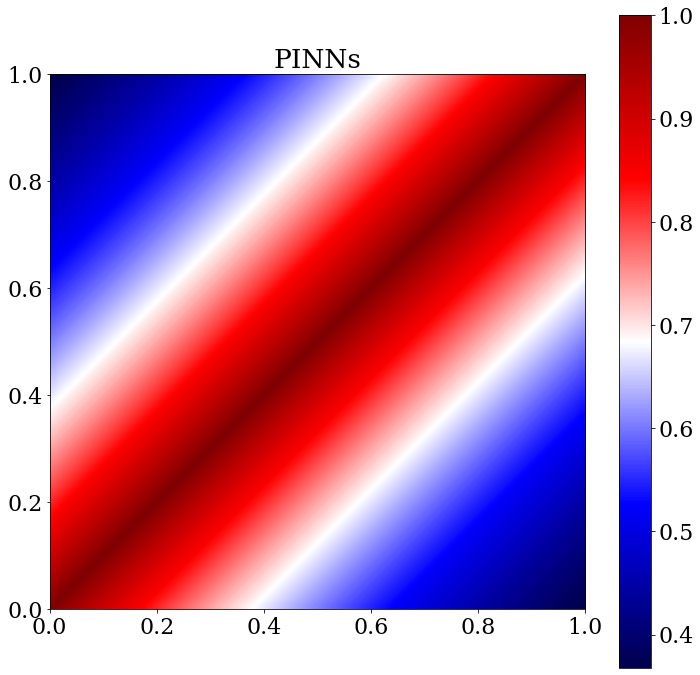

In [32]:

    from matplotlib import pyplot as plt
'''            Evaluate field over a specified grid of points              '''
# Square grid with 10 points per wavelength in each direction
Nx = 100
Ny = Nx

# Grid points
xmin, xmax, ymin, ymax = [0,1,0,1]
plot_grid = np.mgrid[xmin:xmax:Nx * 1j, ymin:ymax:Ny * 1j]
points = np.vstack((plot_grid[0].ravel(),
                    plot_grid[1].ravel(),
                    np.zeros(plot_grid[0].size)))

x = points.T

dist = np.abs(x[:, 0:1] - x[:, 1:2]) 
F =  np.exp(- dist)

F = F.reshape((Nx, Ny))    
'''                  Compare against analytical solution                    '''
# Uncomment to perform comparison, takes a few seconds to run


'''                     Plot field and save figure                          '''
plt.rc('font', family='serif', size=22)

fig, (ax1) = plt.subplots(1, 1, sharey=True, figsize = (12,12))

pcm = ax1.imshow(np.fliplr(F).T,
           extent=[0,1,0,1],
           cmap=plt.cm.get_cmap('seismic'), interpolation='spline16', label='PINN')

#ax1.axis('off')
fig.colorbar(pcm, ax = ax1)
ax1.set_title('PINNs')

plt.savefig('solcov.pdf')

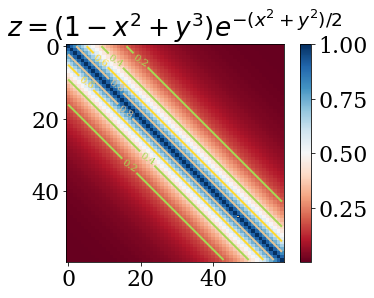

In [6]:
from numpy import exp,arange
from pylab import meshgrid,cm,imshow,contour,clabel,colorbar,axis,title,show

# the function that I'm going to plot
def z_func(x,y):
 return np.exp( - np.abs(x-y) )
 
x = arange(-3.0,3.0,0.1)
y = arange(-3.0,3.0,0.1)
X,Y = meshgrid(x, y) # grid of point
Z = z_func(X, Y) # evaluation of the function on the grid

im = imshow(Z,cmap=cm.RdBu) # drawing the function
# adding the Contour lines with labels
cset = contour(Z,arange(-1,1.5,0.2),linewidths=2,cmap=cm.Set2)
clabel(cset,inline=True,fmt='%1.1f',fontsize=10)
colorbar(im) # adding the colobar on the right
# latex fashion title
title('$z=(1-x^2+y^3) e^{-(x^2+y^2)/2}$')
show()

/usr/local/lib/python3.7/dist-packages/ipykernel_launcher.py:7: MatplotlibDeprecationWarning: Calling gca() with keyword arguments was deprecated in Matplotlib 3.4. Starting two minor releases later, gca() will take no keyword arguments. The gca() function should only be used to get the current axes, or if no axes exist, create new axes with default keyword arguments. To create a new axes with non-default arguments, use plt.axes() or plt.subplot().
  import sys


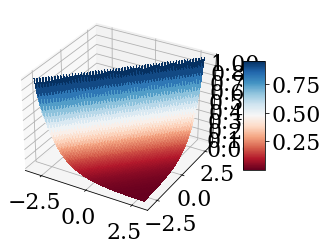

In [7]:
from mpl_toolkits.mplot3d import Axes3D
from matplotlib import cm
from matplotlib.ticker import LinearLocator, FormatStrFormatter
import matplotlib.pyplot as plt

fig = plt.figure()
ax = fig.gca(projection='3d')
surf = ax.plot_surface(X, Y, Z, rstride=1, cstride=1, 
                      cmap=cm.RdBu,linewidth=0, antialiased=False)

ax.zaxis.set_major_locator(LinearLocator(10))
ax.zaxis.set_major_formatter(FormatStrFormatter('%.02f'))

fig.colorbar(surf, shrink=0.5, aspect=5)

plt.show()